<a href="https://colab.research.google.com/github/ayush1011-gsv/PRML2_Lab2/blob/main/PRML_LAB2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np
import pandas as pd

df1 = pd.read_csv("/content/trainingData.csv")
df2 = pd.read_csv("/content/validationData.csv")
df3 = pd.concat([df1,df2], ignore_index=True)

def mean(values):
    return sum(values) / len(values)

def std_dev(values, avg):
    total = 0
    for x in values:
        total += (x - avg) ** 2
    variance = total / (len(values) - 1)
    return variance ** 0.5

def pearson_correlation(x, y):
    if len(x) != len(y) or len(x) <= 1:
        return 0.0

    n = len(x)
    mean_x = mean(x)
    mean_y = mean(y)

    numerator = sum((x[i] - mean_x) * (y[i] - mean_y) for i in range(n)) / (n - 1)
    denominator = std_dev(x, mean_x) * std_dev(y, mean_y)

    if denominator == 0:
        return 0.0

    return numerator / denominator

def calculate_correlation_matrix(df):
    columns = df.columns
    matrix = {}
    for col in columns:
      matrix[col] = {}

    # Convert dataframe to dict of lists once for faster access in the loop
    data_dict = df.to_dict('list')

    for col1 in columns:
        for col2 in columns:
            matrix[col1][col2] = pearson_correlation(
                data_dict[col1], data_dict[col2]
            )
    return matrix

target_cols = ['LONGITUDE', 'LATITUDE', 'FLOOR', 'BUILDINGID']
corr_matrix = calculate_correlation_matrix(df3)

upper_tri = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))
threshold = 0.85

cols_to_drop = [column for column in upper_tri.columns if any(upper_tri[column] > threshold)]
for target in target_cols:
    if target in cols_to_drop:
        cols_to_drop.remove(target)

print(f"Number of redundant features to drop: {len(cols_to_drop)}\n")

df_reduced = df3.drop(columns=cols_to_drop)

print("Original Dataset Shape:\n", df3.shape)
print("Final Dataset Shape:\n", df_reduced.shape)

AttributeError: 'dict' object has no attribute 'where'

In [ ]:
import numpy as np
import sklearn
import pandas as pd

df1 = pd.read_csv("/content/Housing.csv")
pd.set_option('future.no_silent_downcasting', True)
df1 = df1.replace("yes",1)
df1 = df1.replace("no",0)
df1 = df1.replace("furnished",1)
df1 = df1.replace("semi-furnished",0.5)
df1 = df1.replace("unfurnished",0)


def mean(values):
    return sum(values) / len(values)

def std_dev(values, avg):
    variance = sum((x - avg) ** 2 for x in values) / (len(values)-1)
    return variance**0.5

def pearson_correlation(x, y):
    if len(x) != len(y) or len(x) <= 1:
        return 0.0

    n = len(x)
    mean_x = mean(x)
    mean_y = mean(y)

    numerator = sum((x[i] - mean_x) * (y[i] - mean_y) for i in range(n)) / (n - 1)
    denominator = std_dev(x, mean_x) * std_dev(y, mean_y)

    if denominator == 0:
        return 0.0

    return numerator / denominator

def calculate_correlation_matrix(df):
    columns = df.columns
    matrix = {col: {} for col in columns}

    # Convert dataframe to dict of lists once for faster access in the loop
    data_dict = df.to_dict('list')

    for col1 in columns:
        for col2 in columns:
            matrix[col1][col2] = pearson_correlation(
                data_dict[col1], data_dict[col2]
            )
    return matrix

target_col = 'price'

corr_matrix = df1.corr().abs()

upper_tri = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))
threshold = 0.85

cols_to_drop = [column for column in upper_tri.columns if any(upper_tri[column] > threshold)]

if target_col in cols_to_drop:
    cols_to_drop.remove(target_col)

print(f"Features to drop (correlation > {threshold}): {cols_to_drop}\n")

df_reduced = df1.drop(columns=cols_to_drop)

print("Original Dataset Shape:\n", df1.shape)
print("Final Dataset Shape:\n", df_reduced.shape)

pd.set_option("display.max_rows", None)
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 1000)

print(corr_matrix)
sns.heatmap(corr_matrix)




                    price      area  bedrooms  bathrooms   stories  mainroad  guestroom  basement  hotwaterheating  airconditioning   parking  prefarea
price            1.000000  0.535997  0.366494   0.517545  0.420712  0.296898   0.255517  0.187057         0.093073         0.452954  0.384394  0.329777
area             0.535997  1.000000  0.151858   0.193820  0.083996  0.288874   0.140297  0.047417        -0.009229         0.222393  0.352980  0.234779
bedrooms         0.366494  0.151858  1.000000   0.373930  0.408564 -0.012033   0.080549  0.097312         0.046049         0.160603  0.139270  0.079023
bathrooms        0.517545  0.193820  0.373930   1.000000  0.326165  0.042398   0.126469  0.102106         0.067159         0.186915  0.177496  0.063472
stories          0.420712  0.083996  0.408564   0.326165  1.000000  0.121706   0.043538 -0.172394         0.018847         0.293602  0.045547  0.044425
mainroad         0.296898  0.288874 -0.012033   0.042398  0.121706  1.000000   0.092337 

Features to drop (correlation > 0.85): []

Final Dataset Shape:
 (200, 4)
                 TV     Radio  Newspaper     Sales
TV         1.000000  0.054809   0.056648  0.901208
Radio      0.054809  1.000000   0.354104  0.349631
Newspaper  0.056648  0.354104   1.000000  0.157960
Sales      0.901208  0.349631   0.157960  1.000000


<Axes: >

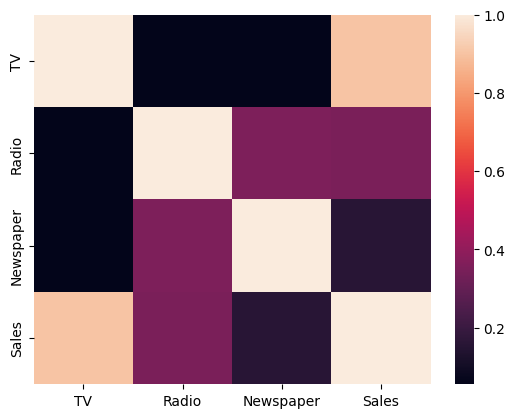

In [ ]:
import numpy as np
import sklearn
import pandas as pd
import seaborn as sns


df = pd.read_csv("/content/advertising.csv")

def mean(values):
    return sum(values) / len(values)

def std_dev(values, avg):
    variance = sum((x - avg) ** 2 for x in values) / (len(values)-1)
    return variance**0.5

def pearson_correlation(x, y):
    if len(x) != len(y) or len(x) <= 1:
        return 0.0

    n = len(x)
    mean_x = mean(x)
    mean_y = mean(y)

    numerator = sum((x[i] - mean_x) * (y[i] - mean_y) for i in range(n)) / (n - 1)
    denominator = std_dev(x, mean_x) * std_dev(y, mean_y)

    if denominator == 0:
        return 0.0

    return numerator / denominator

def calculate_correlation_matrix(df):
    columns = df.columns
    matrix = {col: {} for col in columns}

    # Convert dataframe to dict of lists once for faster access in the loop
    data_dict = df.to_dict('list')

    for col1 in columns:
        for col2 in columns:
            matrix[col1][col2] = pearson_correlation(
                data_dict[col1], data_dict[col2]
            )
    return matrix

target_col = 'Sales'

corr_matrix_dict = calculate_correlation_matrix(df1)
corr_matrix = pd.DataFrame(corr_matrix_dict).abs()

upper_tri = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))
threshold = 0.85

cols_to_drop = [column for column in upper_tri.columns if any(upper_tri[column] > threshold)]

if target_col in cols_to_drop:
    cols_to_drop.remove(target_col)

print(f"Features to drop (correlation > {threshold}): {cols_to_drop}\n")

df_reduced = df1.drop(columns=cols_to_drop)

print("Final Dataset Shape:\n", df_reduced.shape)

pd.set_option("display.max_rows", None)
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 1000)

print(corr_matrix)
sns.heatmap(corr_matrix)

